# Track 1 · Smart Campus Analytics — forecasting hourly building energy use

**Objective.** Predict `energy_usage` for 12 campus buildings (8 types) from building, time, weather, occupancy and
`previous_usage`. Official metric: **RMSE** (lower is better).

**Final package: c18_private_safe.** It preserves **c17**'s linear energy model, test-aware LightGBM
gap-fillers and train-estimated missing-value correction, while recovering building types and isolating fallback
failures. Its supplied-test CSV is byte-identical to **c17 (public RMSE 3.18775)**. **c16 scored 3.18618**, the best
observed public result; c17 replaces its hand-picked offsets with a fixed rule based on labelled training rows.

**Executive summary.** The test set contains about four times as many extreme (but genuine) occupancy /
`previous_usage` values as the training set. On labelled training rows, energy keeps responding *linearly* to such
extremes, so a model that **extrapolates** beats tree models that **saturate** outside the training range.
Error analysis then showed that dropping a missing feature distorts the slopes of the remaining correlated features;
imputing the missing input first lets the *same full* linear model be used on every row. Because the missing test
values come from the test distribution (more spikes), imputers that know they are filling **test** rows, trained with
test-like masking and anomaly ("deviation") features, cut public RMSE a further 0.13. A label-free proxy steered this
and ranked the six c04-c09 submissions in public-score order. Later refinements fixed mask-column ordering, added
cyclic time and residential schedule steps, and corrected bias on naturally missing rows. On complete rows,
validation is close to the estimated noise floor:
out-of-fold residuals could not be predicted by LightGBM, ExtraTrees, CatBoost or an MLP.

*All numbers below are computed in this notebook from the data, the frozen model packages, or the stored experiment
ledger (`experiments/log.jsonl`, `experiments/oof/`, `experiments/proxy_results.csv`). The deployed inference notebook is
separate: `package/c18_private_safe/prediction_notebook.ipynb`.*

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import presentation as P
P.style(); pd.set_option("display.precision", 3)
tr, te = P.load()

## 1 · Problem and data
Features: **building** (`building_id`, `building_type`), **time** (`hour`, `day_of_week`, `month` — no date or year),
**weather** (`temperature`, `humidity`), **occupancy**, **`previous_usage`**. Four numeric features have missing values,
and the test set has **≈3× the missing rate** of train, with far more rows missing two features at once.

In [2]:
P.overview(tr, te)

,train,test
,,
rows,8000,3000
buildings / types,12 / 8,12 / 8
missing previous_usage,1.4%,6.8%
missing occupancy,1.5%,6.9%
missing temperature,1.5%,7.0%
missing humidity,1.5%,6.1%
rows with any missing,5.8%,18.2%
rows with >=2 missing,0.1%,7.7%


**What is `previous_usage`?** The specification calls it the previous period's usage. Its daily profile lines up with energy at the **same hour**
(e.g. the residential step at 21:00 appears at 21:00 in both), not one hour earlier. It behaves like a reference reading
for the same slot in an earlier period. This is an inference from the profiles, not a recovered generator definition.
Section 8 shows that rows do not form a recoverable hourly sequence.

,corr: same hour,corr: one hour back
building_type,,
Administration,0.986,0.918
Business,0.989,0.963
Engineering,0.970,0.940
LectureHall,0.923,0.856
Library,0.908,0.851
Residential,0.969,0.515
Science,0.977,0.947
Sports,0.824,0.803


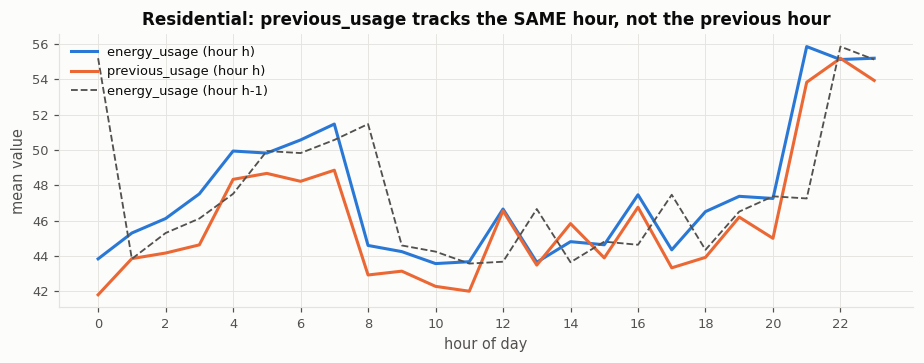

In [3]:
tab, fig = P.prev_semantics(tr, te); tab

## 2 · What drives energy?
Strong daily schedules that differ by building type, plus close relationships with `previous_usage` and occupancy.

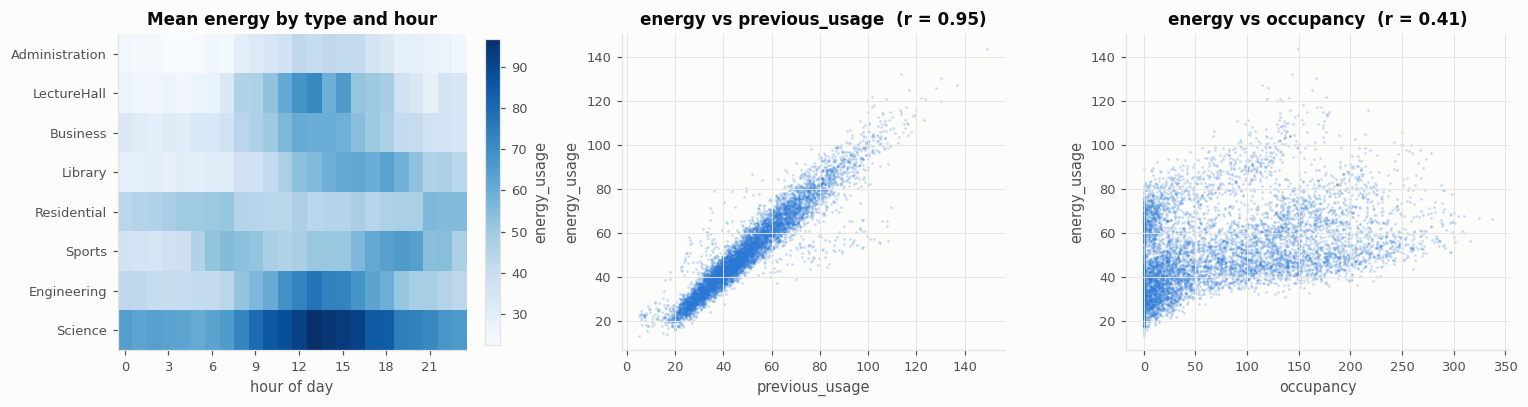

In [4]:
fig = P.fig_drivers(tr)

## 3 · The key discovery: train/test distribution shift
A **target-free** consistency model predicts each feature from the others; a row is a *spike* when a feature deviates by
|z| > 3. Test has four times train's spike rate, and larger spikes. The spikes follow a **schedule**: `previous_usage`
spikes at 22:00–23:00 and 00:00–04:00, occupancy spikes at 07:00–09:00 and never at night. *(Observation; we do not
claim a physical cause.)*

,train,test
,,
any spike (|z|>3),0.041,0.166
previous_usage |z|>3,0.018,0.066
occupancy |z|>3,0.018,0.082
temperature |z|>3,0.006,0.025
previous_usage z 99.9th pct,6.712,7.277
occupancy z 99.9th pct,6.115,8.613


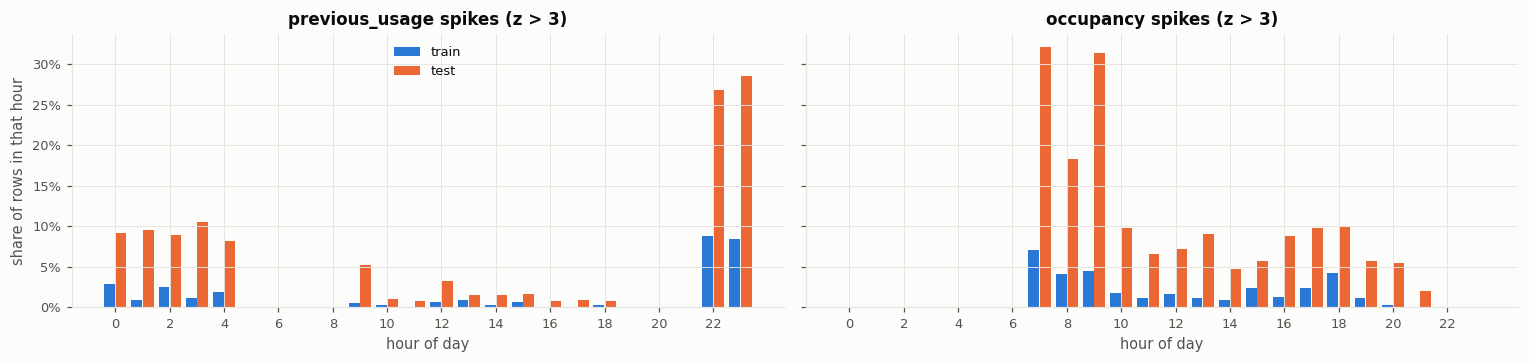

In [5]:
zt, ze = P.feature_z(tr, te)
display(P.spike_summary(zt, ze))
fig = P.fig_spike_schedule(tr, te, zt, ze)

## 4 · Are the spikes errors? No — energy follows them
For each feature we predict energy **without** it (out-of-fold), then plot the unexplained energy against the feature's
deviation. If spikes were corrupt values, the orange points would sit near zero. Instead they continue the line fitted on
**ordinary rows only**. *An extreme value is not a corrupted value.*

,train spike rows,"corr(z, unexplained energy) on spike rows"
feature,,
previous_usage,147,0.918
occupancy,144,0.801


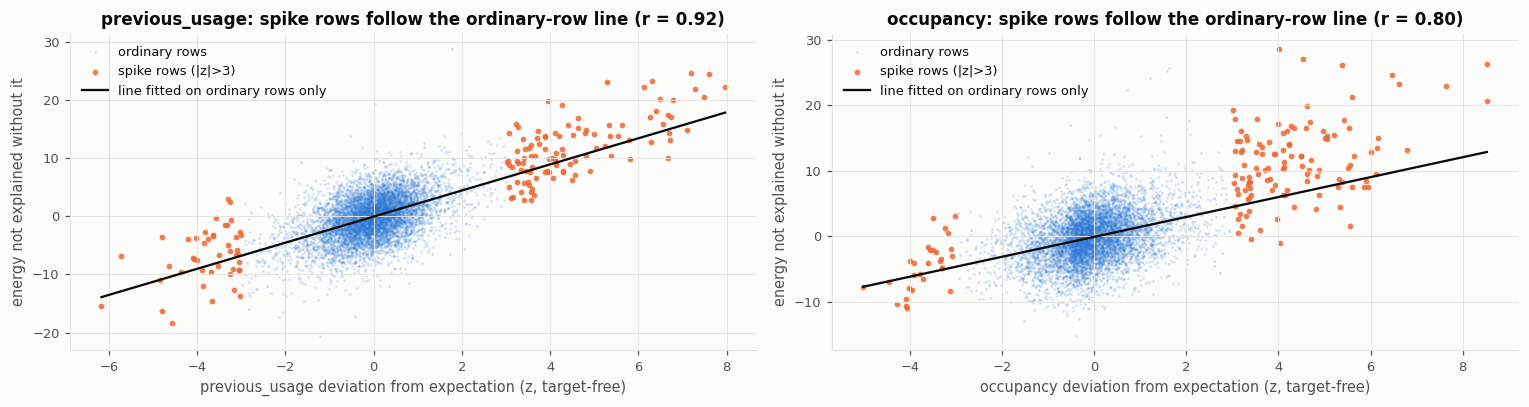

In [6]:
stats, fig = P.spikes_are_real(tr, zt); stats

## 5 · Why extrapolation matters
Tree models split the observed feature range, so beyond the training maximum they reuse the last leaf value.
A linear model keeps its slope. Because test holds more extreme values than train, this difference shows up directly
in the error.

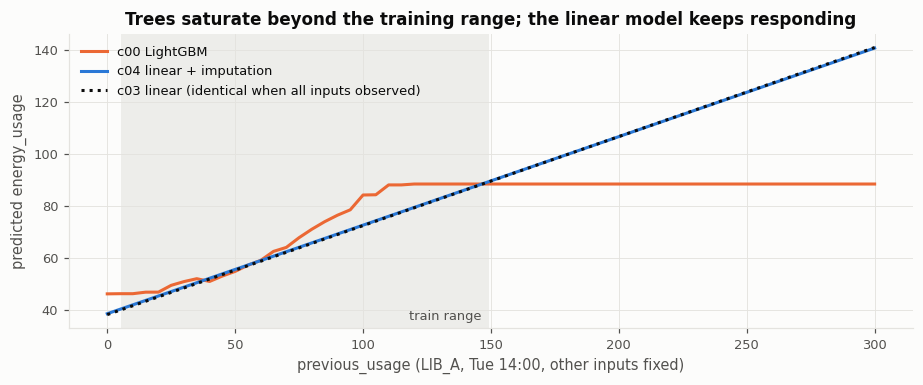

In [7]:
fig = P.fig_extrapolation(tr)

## 6 · Validation design
Ordinary CV underestimates test difficulty, because test has more missing values and more spikes. So every model is
scored on paired splits in three ways (**5-fold × 4 repeats** for confirmed linear comparisons; the tree baseline
uses 2 repeats):

| View | What it does |
|---|---|
| **Clean** | standard repeated K-fold |
| **Test-like** | each validation row gets a missingness mask drawn from the *test file's* joint missing-pattern distribution |
| **Shift-weighted** | test-like, with spike rows up-weighted (×4.05) to test's spike frequency |

A separate train-vs-test classifier on feature values (AUC ≈ 0.70, features only) independently gave train spike rows
about 3× the weight of ordinary rows, which supports the shift-weighting.

## 7 · Model evolution and results
- **c00 — LightGBM:** strong in-distribution, but collapses on missing values and spikes.
- **c03 — structured linear model:** per-building intercept, occupancy and temperature slopes; shared `previous_usage`
  and humidity slopes; smooth daily profile per building type; weekend shape; annual season; *one reduced sub-model per
  missing-value pattern*.
- **c04:** error analysis of c03 (below) → impute missing inputs with target-free LightGBM imputers, then always use the
  **full** linear model; plus restrained hour-by-hour corrections for schedule steps (residential 08:00 / 21:00).

In [8]:
t, paired, ci = P.results_table()
display(t.style.format("{:.3f}", na_rep="—").set_caption("RMSE (mean over CV repeats); public LB where submitted"))
display(paired[["ref", "cand", "mean_delta", "wins"]].rename(columns={"ref": "c03", "cand": "c04", "mean_delta": "Δ (c04 − c03)", "wins": "c04 wins"}).style.format({"c03": "{:.3f}", "c04": "{:.3f}", "Δ (c04 − c03)": "{:+.3f}"}))
print(f"Test-like MSE change c04 vs c03: {ci['masked_mse_delta']:+.3f}, bootstrap 95% CI [{ci['ci95'][0]:+.3f}, {ci['ci95'][1]:+.3f}]")

,clean,test-like,shift-weighted,spike rows,non-spike rows,public LB
model,,,,,,
c00 LightGBM (5x2),3.341,3.964,4.281,5.967,3.854,—
c03 linear,3.077,3.296,3.543,4.875,3.211,3.369
c04 linear + imputation,3.048,3.228,3.363,4.150,3.182,3.337


,c03,c04,Δ (c04 − c03),c04 wins
clean,3.077,3.048,-0.029,4/4
masked,3.296,3.228,-0.068,4/4
shiftW,3.543,3.363,-0.180,4/4
densityW,3.722,3.439,-0.283,4/4
spike_masked,4.875,4.150,-0.725,4/4
nonspike_masked,3.211,3.182,-0.029,4/4


Test-like MSE change c04 vs c03: -0.447, bootstrap 95% CI [-0.666, -0.255]


**External confirmation.** Public RMSE improved from **3.36875 (c03)** to **3.33681 (c04)**. CV predicted the same
direction; the size (−0.032 vs −0.068 predicted) lies within about one standard error of the public-set noise, and
imputation is harder on test rows than on train rows, so a smaller transfer is expected.

### c03's failure mode — and the c04 fix
When occupancy is missing, c03 falls back to a sub-model without it. `previous_usage` is correlated with occupancy, so
in that sub-model it **absorbs part of the occupancy effect** and its slope inflates. On a `previous_usage` spike the
inflated slope then extrapolates wrongly. c04 imputes occupancy instead, so `previous_usage` keeps its own slope.

In [9]:
slopes, row, ctx = P.c03_failure_example()
display(slopes)
display(row)
ctx.round(1)

,effective slope on previous_usage
c03 full model (occupancy observed),0.341
c03 sub-model when occupancy is missing,0.462


,building_id,building_type,hour,day_of_week,month,temperature,humidity,occupancy,previous_usage,c03_pred,c04_pred
1095,ENG_A,Engineering,9,Monday,4,28.6,79.5,NaN,27.4,50.0,62.0


train rows in that building / hour±1 / day-type     65.0
mean energy_usage                                   62.6
mean previous_usage                                 58.7
mean occupancy                                     102.4
dtype: float64

Largest c03→c04 change on the test set: occupancy is missing and `previous_usage` is unusually low. c03's inflated slope
drags the prediction down to 50.0; c04 predicts 62.0, close to the 62.6 typical of that building / hour / day-type.

*Why imputation helps:* the energy equation is linear in occupancy and previous usage. Conditional means are the right
inputs for those terms; temperature has a small quadratic term, so mean imputation is an approximation there.
The imputers use features only (train + unlabelled test features; evaluated feature values are held out in the proxy).
LightGBM estimates missing inputs; the energy model retains its linear response to occupancy and previous usage.

## 7b · Test-aware imputation (c05 → c09): the second big gain
Error budget after c04: rows **without** missing values (82% of test) sit at the noise floor (~3.0, section 8);
rows **with** a missing value (18%) carry the remaining error. A missing *test* value comes from the **test**
distribution, which has ~4× train's spike rate, but c04's imputers pooled train and test and so under-filled test
values (held-out test-row occupancy bias −4.7). Steps, all target-free:

- **c05 domain flag:** imputers get a feature `dom` (train 0 / test 1) and predict with `dom=1` → bias −4.7 → −0.4.
- **c06–c07:** average of 3 imputer settings; test rows weighted ×2 (×3+ overshoots).
- **c08 mask augmentation ×5:** training copies with test-like co-missingness, so imputers learn to work when
  several inputs are missing at once (real test rows often are).
- **c09 deviation features:** each observed input minus its building×hour and building mean (lookup tables built
  from features). Spikes co-occur across features, so an unusual observed value is evidence about a missing one.

**How we validated without test labels.** Hide *observed* values in held-out public-test rows (with test-like
co-missingness), re-impute them, and weight each error by that feature's energy slope for the building. Since the
dominant energy terms are linear, this gives a useful imputation-error proxy using **no test targets**. It is not the
final RMSE: joint missing-feature errors can be correlated, temperature is slightly nonlinear, and genuinely missing
values cannot be checked directly.

,change,public RMSE,Δ vs previous
candidate,,,
c03_linear_v3,"c03 linear, per-pattern sub-models",3.36875,—
c04_linear_imputed,c04 + LightGBM imputers (train+test pooled),3.33681,-0.03194
c05_domain_imputed,c05 + domain flag (impute as test),3.25549,-0.08132
c06_domain_ens,c06 + 3-imputer average,3.23804,-0.01745
c07_domain_ens_testw2,c07 + test rows x2,3.23149,-0.00655
c08_domain_ens_aug5,c08 + mask augmentation x5,3.20937,-0.02212
c09_dev_imputed,c09 + deviation features,3.20392,-0.00545
c11_v5_cyclic,"c11 mask-order fix, cyclic time, residential steps",3.19406,-0.00986
c12_v5_cyclic_prevoff,c12 previous_usage missing offset,3.18937,-0.00469


,test-row proxy,proxy on naturally-incomplete rows,train-row proxy,public RMSE
candidate,,,,
c04,25.851,nan,13.005,3.337
c05,23.040,30.340,12.691,3.255
c06,22.650,30.007,12.470,3.238
c07,22.608,29.878,12.550,3.231
c08,22.214,28.574,12.557,3.209
c09,20.866,27.627,12.155,3.204


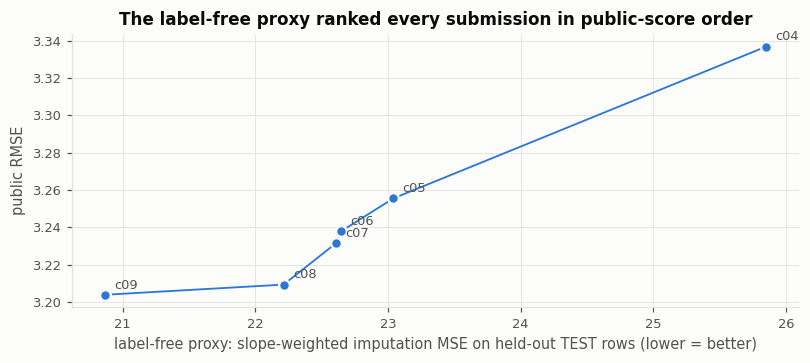

In [10]:
display(P.public_progression().style.format({"public RMSE": "{:.5f}", "Δ vs previous": "{:+.5f}"}, na_rep="—"))
pt = P.proxy_table(); display(pt.style.format("{:.3f}"))
fig = P.fig_proxy_vs_public(pt)

The proxy ranked the six c04-c09 submissions correctly; its magnitude is less reliable (c09's gain transferred only
−0.005). The naturally-incomplete-row slice better reflects hard test rows; neither proxy observes genuinely missing
values. Later MNAR decisions therefore used naturally missing **labelled training rows**.

## 7c · Final statistical model and private-test package
**c11:** fix mask-column ordering; add cyclic time to imputers; fit residential day/night steps and stronger shrinkage
of hour corrections. The next table measures the **energy model on complete rows**, not full c17 pipeline CV.

In [11]:
display(P.final_energy_cv())
display(P.final_mnar_table().round(3))

,complete-row RMSE,repeat RMSEs,rows
model,,,
V4 (c04-c09),3.005,"[3.006443562401091, 3.0061467167839773, 3.0008...",7537
V5 (c11-c18),2.998,"[2.999348326922101, 2.9996563824181224, 2.9934...",7537


,raw kappa,SE,shrunk kappa
previous_usage,0.418,0.153,0.297
occupancy,0.154,0.175,0.101
temperature,-0.196,0.221,-0.106
humidity,1.464,1.561,0.034


**c17:** estimate missing-feature shifts on naturally missing training rows using out-of-fold energy residuals;
shrink the four estimates toward zero with empirical Bayes. Apply `kappa × energy slope × conditional SD` when
an input is missing. Previous usage has the strongest train support (raw kappa 0.418, SE 0.153).
The correction's cross-fitted MSE change is only −0.078 (SE 0.126) on single-missing training rows, so its benefit
remains uncertain. Transferring train shifts to private-test rows is an explicit assumption.

**c18:** reuse c17's trained parameters and repair input handling. A known building ID supplies its type when missing
or malformed. A failed imputer leaves only that feature for the matching linear sub-model; if the energy model fails,
return the finite training mean. Tests cover all 16 numeric missingness patterns across 12 buildings.

**Selection:** c16 has the best recorded public RMSE, but its offsets were partly chosen by judgement and public scores.
c17's fixed train-estimated rule avoids selecting offset sizes on public results. c18's CSV is identical to c17;
its input recovery has no separately measured private-test score.

### Reproducibility: rebuild the complete statistical pipeline from the raw files
This cell refits the energy model, all 12 imputer members, five-fold conditional variances and train-only MNAR
calibration. It does not load previous experiment outputs for fitting. Expect a few minutes of CPU work.

In [12]:
import time
from build_package import predict_inprocess
from candidates.c18_private_safe import PREDICT_CODE
from train_final import rebuild_statistical_model
t0 = time.time(); art, calibration = rebuild_statistical_model(tr, te)
fresh = predict_inprocess(art, PREDICT_CODE, te)
frozen = pd.read_csv("../submissions/c18_private_safe.csv").prediction.to_numpy()
max_diff = float(np.abs(fresh - frozen).max())
assert np.allclose(fresh, frozen, rtol=0, atol=1e-8), max_diff
print(f"full rebuild in {time.time()-t0:.0f}s; max |fresh - frozen| = {max_diff:.2e}")
display(P.final_summary())
display(calibration)

conditional-variance fold 1/5


conditional-variance fold 2/5


conditional-variance fold 3/5


conditional-variance fold 4/5


conditional-variance fold 5/5


...

energy calibration repeat 3/4


energy calibration repeat 4/4


full rebuild in 40s; max |fresh - frozen| = 2.84e-14


{'candidate': 'c18_private_safe',
 'statistical_candidate': 'c17_mnar_eb',
 'source_public_rmse': 3.18775,
 'best_public_candidate': 'c16_prev06_occ_selfmask',
 'best_public_rmse': 3.18618,
 'byte_identical_source_csv': True,
 'separate_public_submission': False,
 'submission_sha256': '05cb6f912cc74abc5285f7fc65cfdd08575666ae86da93ad03dda5a4493490f1',
 'rows': 3000,
 'prediction_min': 14.06956515118462,
 'prediction_max': 131.66438622685675,
 'model_bytes': 19702570,
 'mnar_kappa': {'previous_usage': 0.2967938726832853,
  'occupancy': 0.10051928720414387,
  'temperature': -0.10594236977127372,
  'humidity': 0.03376532701084684},
 'package': 'package/c18_private_safe'}

{'raw_kappa_se': {'previous_usage': (0.4177096749462626, 0.15305516428765062),
  'occupancy': (0.15402217653636446, 0.1749435117711976),
  'temperature': (-0.19628638174436797, 0.22143627496935192),
  'humidity': (1.4641299312396832, 1.560708585863712)},
 'tau2': 0.0575,
 'complete_oof_rmse': 2.9940614080931187}

## 8 · Error analysis — is anything left?
We took c04's **out-of-fold** residuals and asked whether any model can predict them out of sample.
The models tested had R² < 0. This supports a small remaining signal on the train distribution; it does not prove
the generator is irreducibly random or that no better method exists.

In [13]:
r2, shrink = P.residual_predictability()
print(f"LightGBM on c04 OOF residuals: out-of-sample R² = {r2:+.4f}")
shrink.T

LightGBM on c04 OOF residuals: out-of-sample R² = -0.0185


correction weight,0.0,0.2,0.4,0.6,0.8,1.0
RMSE of c04 + weight x correction,3.043,3.045,3.049,3.054,3.062,3.071


| Hypothesis tested (paired vs c04, test-like Δ RMSE) | Result | Conclusion |
|---|---|---|
| Residual model: LightGBM / ExtraTrees / CatBoost / MLP | R² −0.019 / −0.011 / −0.005 / −0.004 | no learnable residual signal |
| Group-specific slopes (prev, occupancy × type / building / hour band / weekend; temperature hinges) | +0.0005 to +0.004 | slopes are shared |
| Separate slope for spiked values (deviation features) | +0.0005 (CI spans 0) | spikes respond like ordinary values |
| Train/test density-ratio or spike weighting in the fit | +0.002 to +0.018 | worse |
| Alternative imputers (ExtraTrees, LGB+ET, chained) | +0.004 to +0.068 | LightGBM imputers best |
| Train-only imputers (no test features) | +0.005 | worse; no safer on train-like rows |
| c03/c04 blend, c04 + LightGBM energy blend | at most 0.004 better test-like; worse shift-weighted & spikes | rejected |
| Log target / WLS / ridge α 1 or 10 | worse | additive, homoscedastic-enough, α=3 |

*(Values from `experiments/NOTES.md` / `log.jsonl`.)*

### Data forensics — no hidden sequence
If rows were consecutive hours, a row's target would reappear as the next hour's `previous_usage`. It does not: the
exact-match rate at +1 h equals the control offsets, and ID order carries no structure. Rows behave as independent
samples, so sequence or time-series methods have nothing to exploit.

In [14]:
chain, idt = P.forensics(tr, te)
display(chain.style.format({"exact match rate": "{:.2%}"}))
idt.style.format("{:.1%}")

,train rows with a candidate,exact match rate
offset,,
+1 h (the chaining hypothesis),2951,0.51%
+0 h (control),2880,0.49%
-1 h (control),2899,0.66%
+2 h (control),2843,0.67%
+5 h (control),2933,0.31%


,observed,chance
check,,
"consecutive ids, same building",8.1%,8.5%
"consecutive ids, one hour apart",3.9%,4.2%


## 9 · Campus insights (from the final model's linear energy equation)
Coefficients describe **associations** in this dataset, not proven causal effects.

,type,+100 occupants,+1 °C (at 28 °C),weekend vs Tue (noon),"base load (03:00, empty, prev=0, 26 °C)"
building,,,,,
ADM_A,Administration,8.5,1.4,-2.2,15.7
BUS_A,Business,10.4,1.6,-2.8,20.2
BUS_B,Business,9.9,1.7,-3.5,24.0
ENG_A,Engineering,11.3,1.9,-0.2,27.3
ENG_B,Engineering,10.9,1.8,0.4,24.5
LEC_A,LectureHall,13.4,1.5,-2.7,17.0
LIB_A,Library,7.8,1.5,0.2,19.4
RES_A,Residential,4.6,1.5,-0.3,25.4
RES_B,Residential,4.4,1.4,0.4,23.5


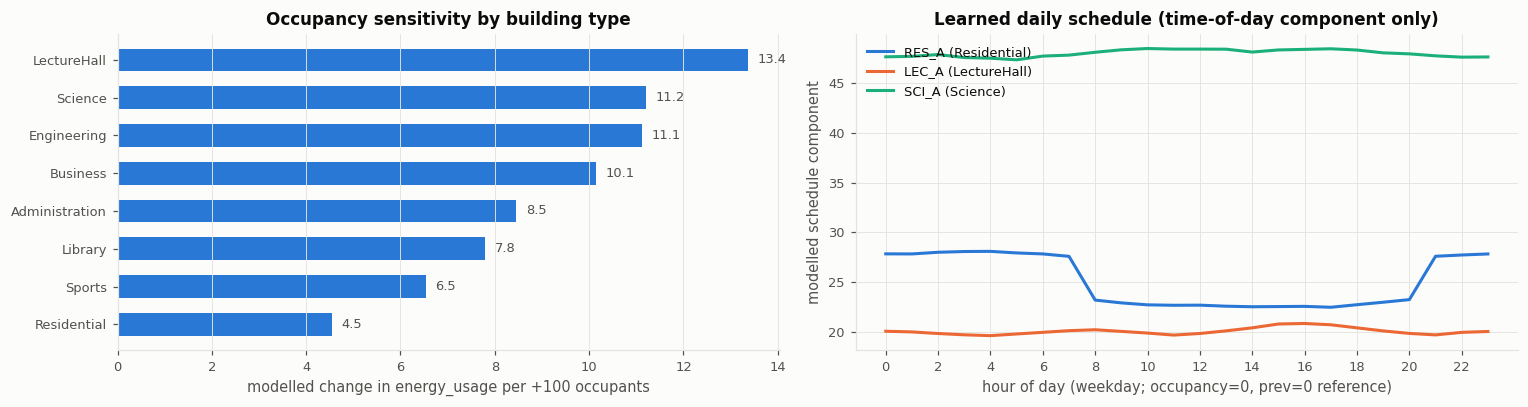

In [15]:
eff = P.campus_effects()
display(eff.drop(columns=["+10 previous_usage"]).round(1))
fig = P.fig_campus(eff, tr)

- **Occupancy sensitivity varies about 3×:** each additional 100 occupants is associated with **+13.4** energy units
  in the lecture hall but only **+4.4–4.7** in residences. Lecture-hall energy is the most occupancy-driven.
- **Base load:** science buildings have the largest modelled base load (**≈39–43** at the model's empty, low-history
  03:00 reference, vs **≈16–27** elsewhere). This is *consistent with* energy-intensive fixed loads (interpretation).
- **Schedules:** residences step **down at 08:00** and **up at 21:00**. These steps were sharp enough that hour-level
  corrections improved the model.
- **Temperature:** +1 °C is associated with +1.4 to +2.4 units (largest in science buildings), a cooling-type response.
- **Spike scheduling:** extreme `previous_usage` values cluster late at night and extreme occupancy in the morning;
  their marginal relationship with energy matches ordinary values, so c04 applies the same linear response.

**How this could support operations:** hourly forecasts for peak-demand planning; flagging buildings whose metered use
exceeds the model's expectation (possible faults or waste); prioritising occupancy-driven buildings for demand-based
HVAC/lighting control; monitoring base load in science buildings.

## 10 · Limitations
- Private/test spikes may exceed the labelled training range. The linear response is verified only up to the largest
  train spikes; beyond that it is a **modelling assumption** (the most defensible one given train evidence).
- Imputers cannot reconstruct an unpredictable spike in a *missing* feature, so those rows keep a higher error.
- With no date or year, no external weather or calendar data could be joined.
- Test-aware imputers assume private input relationships resemble the public feature distribution. Good train-domain
  proxy performance does not guarantee good private-domain performance: inference predicts with the test-domain flag.
- The MNAR shift assumes the train-estimated mechanism transfers. Its cross-fitted improvement is uncertain; public
  differences of a few thousandths are insufficient evidence for a private improvement.
- The remaining residual appears unlearnable from the given features; coefficients are associations, not causal effects.

## 11 · The final choice and the latest experiments
The linear model preserves the measured response to extreme values. Gap-fillers keep the full observed-feature slopes,
and the fixed train-only MNAR rule accounts for missing-value bias. The c18 package adds recoverable input handling.

Two additional five-fold, target-free checks did not justify replacing c17: extrapolating gap-fillers worsened the
test-feature proxy (20.81 → 21.26 for a fixed residual blend); a fixed blend with energy-weighted gap-fillers improved
it slightly (20.81 → 20.73), but its paired 95% interval for MSE change includes zero (−0.177 to +0.027).
These are proxy values, not leaderboard RMSE. Neither variant was submitted or promoted.

**Use `package/c18_private_safe/` for inference and the one-page PDF for the technical report.** The team still needs
to upload the artifacts and confirm the portal's actual private execution.